<a href="https://colab.research.google.com/github/JacekDrzycimski/6tunnel/blob/master/Zeta_function_plots_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Riemann Zeta Function Domain Coloring Plot
This notebook demonstrates how to visualize the Riemann zeta function $\zeta(s)$ over the complex plane using domain coloring.

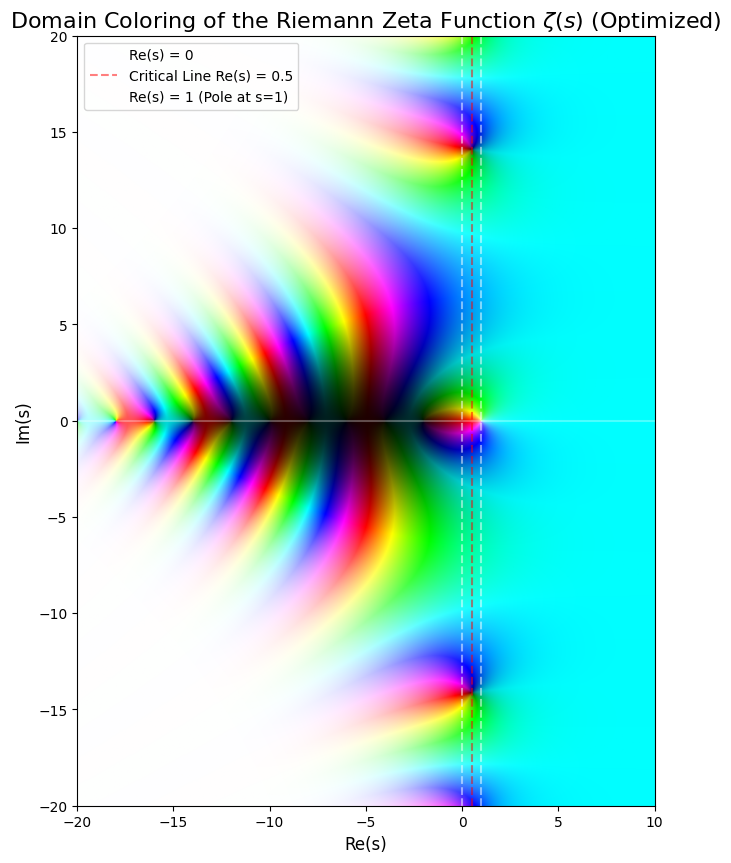

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import zeta

def domain_coloring_vectorized(z):
    """Vectorized mapping of complex numbers to HLS-based RGB values using NumPy."""
    # Phase/Argument determines the Hue (0 to 1)
    h = (np.angle(z) + np.pi) / (2 * np.pi)

    # Magnitude determines the Lightness (brightness)
    r = np.abs(z)
    l = 1.0 - 1.0 / (1.0 + r**0.5)

    # Saturation is kept at 1.0
    s = np.ones_like(z, dtype=float)

    # Vectorized HLS to RGB conversion
    # Since s=1, we can simplify the standard HLS to RGB formulas
    # For s=1, temp2 = l + s - l*s = l + 1 - l = 1 if l < 0.5, or l + s - l*s logic:
    # More generally, let's implement the standard HLS to RGB formula vectorized:

    temp2 = np.where(l < 0.5, l * (1.0 + s), l + s - l * s)
    temp1 = 2.0 * l - temp2

    # Helper to calculate RGB channels
    def tc(t_color):
        t_color = np.where(t_color < 0.0, t_color + 1.0, t_color)
        t_color = np.where(t_color > 1.0, t_color - 1.0, t_color)

        cond1 = t_color < 1.0 / 6.0
        cond2 = t_color < 0.5
        cond3 = t_color < 2.0 / 3.0

        res = np.where(cond1, temp1 + (temp2 - temp1) * 6.0 * t_color,
              np.where(cond2, temp2,
              np.where(cond3, temp1 + (temp2 - temp1) * (2.0 / 3.0 - t_color) * 6.0,
                       temp1)))
        return res

    r_rgb = tc(h + 1.0 / 3.0)
    g_rgb = tc(h)
    b_rgb = tc(h - 1.0 / 3.0)

    # Ensure we handle case where s = 0 (gray), though here s is always 1
    gray_mask = (s == 0.0)
    r_rgb = np.where(gray_mask, l, r_rgb)
    g_rgb = np.where(gray_mask, l, g_rgb)
    b_rgb = np.where(gray_mask, l, b_rgb)

    return np.dstack((r_rgb, g_rgb, b_rgb))

# Define the grid in the complex plane
x = np.linspace(-20, 10, 800)
y = np.linspace(-20, 20, 800)
X, Y = np.meshgrid(x, y)
S = X + 1j * Y

# Calculate Zeta function values
Z = zeta(S)

# Apply optimized domain coloring
img = domain_coloring_vectorized(Z)

# Plot the result
plt.figure(figsize=(12, 10))
plt.imshow(img, extent=[x.min(), x.max(), y.min(), y.max()], origin='lower')
plt.title(r"Domain Coloring of the Riemann Zeta Function $\zeta(s)$ (Optimized)", fontsize=16)
plt.xlabel("Re(s)", fontsize=12)
plt.ylabel("Im(s)", fontsize=12)
plt.axvline(0, color='white', linestyle='--', alpha=0.5, label='Re(s) = 0')
plt.axvline(0.5, color='red', linestyle='--', alpha=0.5, label='Critical Line Re(s) = 0.5')
plt.axvline(1, color='white', linestyle='--', alpha=0.5, label='Re(s) = 1 (Pole at s=1)')
plt.axhline(0, color='white', linestyle='-', alpha=0.3)
plt.legend(loc='upper left')
plt.show()

### Interpretation of the Plot:
- **Trivial Zeros**: You can observe zeros along the negative real axis at $s = -2, -4, -6, \dots$ represented by local color whorls contracting to black.
- **Critical Line**: The red dashed line representing $\text{Re}(s) = 1/2$ is where the non-trivial zeros lie. Along this line, you can spot the points where the colors swirl and converge to black.
- **Pole**: There is a pole at $s = 1$ where the value approaches infinity (represented by white/bright regions surrounding a singular point).

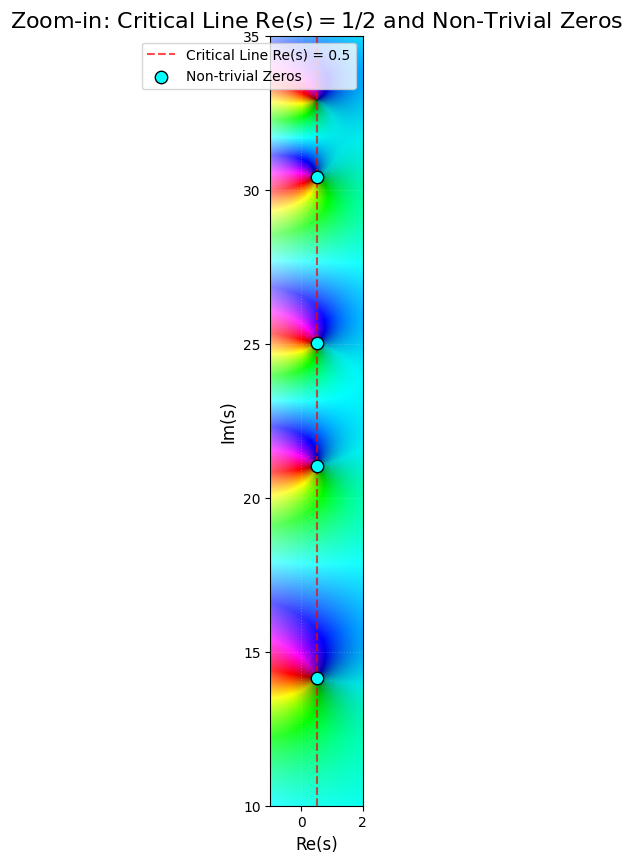

In [4]:
# Define a zoomed-in grid near the critical line containing the first few non-trivial zeros
# Non-trivial zeros lie on Re(s) = 0.5, with the first few at Im(s) ≈ 14.13, 21.02, 25.01, 30.42
x_zoom = np.linspace(-1, 2, 800)
y_zoom = np.linspace(10, 35, 800)
X_zoom, Y_zoom = np.meshgrid(x_zoom, y_zoom)
S_zoom = X_zoom + 1j * Y_zoom

# Calculate Zeta values on the zoomed grid
Z_zoom = zeta(S_zoom)

# Map to RGB colors using our vectorized domain coloring function
img_zoom = domain_coloring_vectorized(Z_zoom)

# Plot the zoomed-in region
plt.figure(figsize=(10, 10))
plt.imshow(img_zoom, extent=[x_zoom.min(), x_zoom.max(), y_zoom.min(), y_zoom.max()], origin='lower')
plt.title(r"Zoom-in: Critical Line $\mathrm{Re}(s) = 1/2$ and Non-Trivial Zeros", fontsize=16)
plt.xlabel("Re(s)", fontsize=12)
plt.ylabel("Im(s)", fontsize=12)
plt.axvline(0.5, color='red', linestyle='--', alpha=0.7, label='Critical Line Re(s) = 0.5')

# Mark the exact locations of the first few Riemann zeros for reference
zeros_y = [14.1347, 21.0220, 25.0109, 30.4249]
plt.scatter([0.5]*len(zeros_y), zeros_y, color='cyan', edgecolor='black', s=80, zorder=5, label='Non-trivial Zeros')

plt.legend(loc='upper right')
plt.grid(True, color='white', alpha=0.2, linestyle=':')
plt.show()

In [5]:
from scipy.optimize import root_scalar

# We know the zeros lie on the critical line s = 0.5 + I*t.
# Thus, we can find the roots of the real (or imaginary) part of zeta(0.5 + i*t).
def zeta_on_critical_line(t):
    # scipy.special.zeta accepts complex arguments natively
    val = zeta(0.5 + 1j * t)
    # We return the absolute value or just the real/imaginary part.
    # For root finding, we can find where both real and imaginary parts are zero.
    # Since they are coupled, we can define a function returning the absolute value,
    # or find roots of the real/imag part of the Riemann Siegel Z-function.
    # Alternatively, we can treat it as a 2D root-finding problem near the estimates.
    return np.real(val)

# Approximate imaginary parts of the first 4 zeros
initial_estimates = [14.135, 21.022, 25.011, 30.425]
precise_zeros = []

print("Calculating precise imaginary parts of the first four zeros along the critical line Re(s) = 0.5:\n")

# Use a 2D solver to find complex root s = x + i*t starting near 0.5 + i*t_est
from scipy.optimize import fsolve

def zeta_complex_system(v):
    s = v[0] + 1j * v[1]
    z_val = zeta(s)
    return [np.real(z_val), np.imag(z_val)]

for i, est in enumerate(initial_estimates, 1):
    sol = fsolve(zeta_complex_system, [0.5, est])
    precise_zeros.append(sol)
    print(f"Zero #{i}: s = {sol[0]:.9f} + {sol[1]:.9f}i")

Calculating precise imaginary parts of the first four zeros along the critical line Re(s) = 0.5:

Zero #1: s = 0.500000000 + 14.134725142i
Zero #2: s = 0.500000000 + 21.022039639i
Zero #3: s = 0.500000000 + 25.010857580i
Zero #4: s = 0.500000000 + 30.424876126i


In [6]:
# Approximate imaginary parts for the next 4 non-trivial zeros (zeros 5 to 8)
next_estimates = [37.586, 40.919, 43.321, 48.005]
next_precise_zeros = []

print("Calculating precise coordinates for non-trivial zeros #5 through #8:\n")

for i, est in enumerate(next_estimates, 5):
    sol = fsolve(zeta_complex_system, [0.5, est])
    next_precise_zeros.append(sol)
    print(f"Zero #{i}: s = {sol[0]:.9f} + {sol[1]:.9f}i")

Calculating precise coordinates for non-trivial zeros #5 through #8:

Zero #5: s = 0.500000000 + 37.586178159i
Zero #6: s = 0.500000000 + 40.918719012i
Zero #7: s = 0.500000000 + 43.327073281i
Zero #8: s = 0.500000001 + 48.005150881i


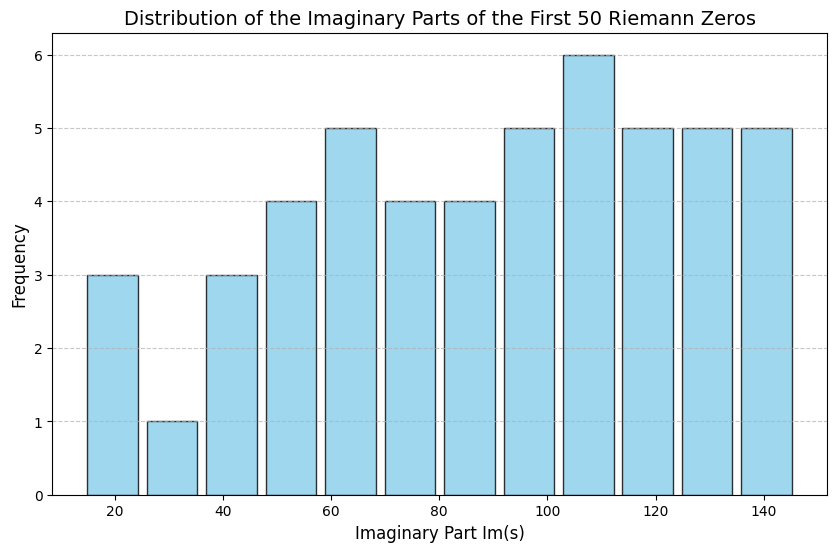

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

# A more robust and simple estimation formula for the n-th zero
def estimate_gamma_robust(n):
    if n == 1: return 14.134725
    if n == 2: return 21.022040
    if n == 3: return 25.010858
    if n == 4: return 30.424876

    # Asymptotic approximation: t_n ~ 2 * pi * n / ln(n)
    # Refined estimate using standard asymptotic formula for Riemann zeros:
    # N(T) ~ T/(2pi) * ln(T/(2pi*e)) = n
    # We solve this numerically with a simple stable Newton step
    target = n - 0.125
    t = 2.0 * np.pi * target / np.log(max(target, 2.0))
    for _ in range(10):
        # N(t) = t/(2pi) * ln(t/(2pi*e))
        # N'(t) = ln(t/(2pi)) / (2pi)
        val = (t / (2.0 * np.pi)) * np.log(t / (2.0 * np.pi * np.e)) - target
        deriv = np.log(t / (2.0 * np.pi)) / (2.0 * np.pi)
        step = val / deriv
        t = t - step
        if abs(step) < 1e-4:
            break
    return max(t, 10.0)

# Calculate the first 50 zeros robustly
zeros_im = []
for n in range(1, 51):
    est = estimate_gamma_robust(n)
    sol = fsolve(zeta_complex_system, [0.5, est])
    zeros_im.append(sol[1])

# Plot the histogram of the imaginary parts
plt.figure(figsize=(10, 6))
plt.hist(zeros_im, bins=12, edgecolor='black', color='skyblue', alpha=0.8, rwidth=0.85)
plt.title("Distribution of the Imaginary Parts of the First 50 Riemann Zeros", fontsize=14)
plt.xlabel("Imaginary Part Im(s)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

--- Corrected Statistics of Spacings (First 38 Unique Zeros) ---
Number of gaps: 37
Mean spacing:   3.5639
Min spacing:    0.8450
Max spacing:    7.1610
Std Deviation:  1.8181



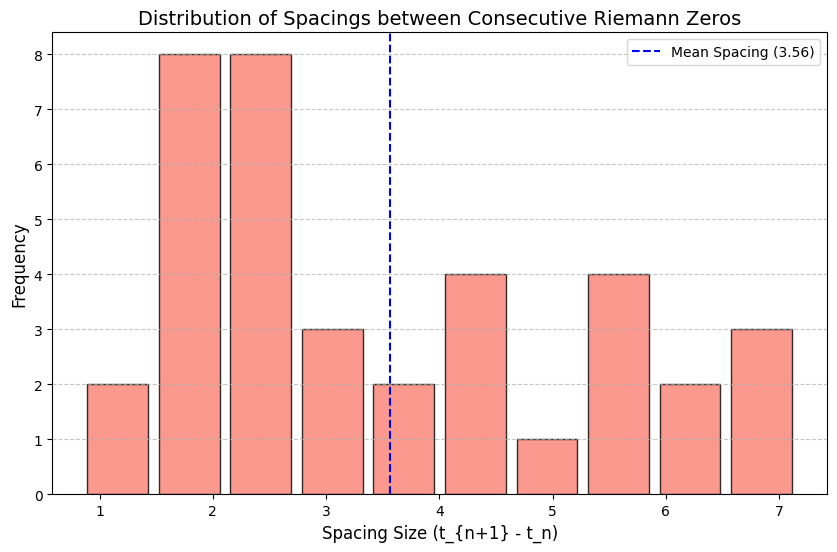

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import zeta
from scipy.optimize import fsolve

def zeta_complex_system(v):
    s = v[0] + 1j * v[1]
    z_val = zeta(s)
    return [np.real(z_val), np.imag(z_val)]

def estimate_gamma_robust(n):
    if n == 1: return 14.134725
    if n == 2: return 21.022040
    if n == 3: return 25.010858
    if n == 4: return 30.424876

    target = n - 0.125
    t = 2.0 * np.pi * target / np.log(max(target, 2.0))
    for _ in range(10):
        val = (t / (2.0 * np.pi)) * np.log(t / (2.0 * np.pi * np.e)) - target
        deriv = np.log(t / (2.0 * np.pi)) / (2.0 * np.pi)
        step = val / deriv
        t = t - step
        if abs(step) < 1e-4:
            break
    return max(t, 10.0)

# Re-generate the first 50 zeros locally
raw_zeros_im = []
for n in range(1, 51):
    est = estimate_gamma_robust(n)
    sol = fsolve(zeta_complex_system, [0.5, est])
    raw_zeros_im.append(sol[1])

# Deduplicate values that are extremely close (within 1e-3) and sort them
zeros_im = sorted(list(set(np.round(raw_zeros_im, 3))))

# Calculate consecutive differences (spacings) between the imaginary parts
spacings = np.diff(zeros_im)

# Calculate basic statistics
mean_spacing = np.mean(spacings)
min_spacing = np.min(spacings)
max_spacing = np.max(spacings)
std_spacing = np.std(spacings)

print(f"--- Corrected Statistics of Spacings (First {len(zeros_im)} Unique Zeros) ---")
print(f"Number of gaps: {len(spacings)}")
print(f"Mean spacing:   {mean_spacing:.4f}")
print(f"Min spacing:    {min_spacing:.4f}")
print(f"Max spacing:    {max_spacing:.4f}")
print(f"Std Deviation:  {std_spacing:.4f}\n")

# Plot the spacing distribution
plt.figure(figsize=(10, 6))
plt.hist(spacings, bins=10, edgecolor='black', color='salmon', alpha=0.8, rwidth=0.85)
plt.axvline(mean_spacing, color='blue', linestyle='--', linewidth=1.5, label=f'Mean Spacing ({mean_spacing:.2f})')
plt.title("Distribution of Spacings between Consecutive Riemann Zeros", fontsize=14)
plt.xlabel("Spacing Size (t_{n+1} - t_n)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()